<a href="https://colab.research.google.com/github/Andres931720/Deberes/blob/main/TAREA_Andres_Vinueza_07MIAR_Transformer2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea 07MIAR – Portafolio Artículo Científico
## Análisis de un Transformer entrenado: GPT-2 y la atención de Vaswani et al.

**Asignatura:** 07MIAR – Redes Neuronales y Deep Learning  
**Autor:** Andrés Vinueza  
**Fecha:** 29/10/2026

Este cuaderno analiza **GPT-2 pequeño**, una implementación entrenada de la arquitectura Transformer descrita en *Attention Is All You Need* (Vaswani et al., 2017). Se presentan: (1) el *model summary* con sus capas y parámetros, (2) la forma y distribución del tensor de entrada y de los logits de salida durante la generación y (3) los mapas de calor de la self-attention para dos ejemplos.

## 1. Artículo y modelo elegido

El artículo propone el **Transformer**, una arquitectura que sustituye las capas recurrentes y convolucionales por **self-attention**: cada token se relaciona con todos los demás en un solo paso y todo se calcula en paralelo. La operación central es

$$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^{T}}{\sqrt{d_k}}\right)V$$

Como **implementación entrenada** se usa **GPT-2 pequeño** (OpenAI; Radford et al., 2019), cargado desde Hugging Face ([openai-community/gpt2](https://huggingface.co/openai-community/gpt2)) con la librería *Transformers* (Wolf et al., 2020). GPT-2 corresponde a la parte *decoder* del Transformer: self-attention con máscara causal y una red feed-forward, repetidas en 12 bloques.

| Característica | Transformer base (paper) | GPT-2 pequeño |
| --- | --- | --- |
| Partes | Encoder + decoder | Solo decoder |
| Bloques | 6 + 6 | 12 |
| d_model | 512 | 768 |
| Cabezas de atención | 8 | 12 |
| d_ff (feed-forward) | 2048 | 3072 |
| Posición | Seno/coseno fijo | Embeddings aprendidos |
| Activación del feed-forward | ReLU | GELU |
| Parámetros | ~65 M | 124.4 M |

**Frases de entrada.** Se usan dos frases en inglés (definidas en la celda de configuración), porque GPT-2 se entrenó casi solo con ese idioma; así cada palabra suele ser un token y los mapas de calor se leen directamente.

In [17]:
# ===================== CONFIGURACIÓN =====================
MODEL_NAME = "gpt2"
USE_4BIT   = False

# Dos frases de entrada. "query" es la palabra cuya atención analizaremos.

SENTENCES = [
    {"text": "The supplier increased the cost, so the retailer had to adjust its margin.", "query": "its"},
    {"text": "The store applied a promotion to the product because it was selling slowly.", "query": "it"},
]


N_NEW_TOKENS = 10

In [18]:
# ===================== INSTALACIÓN =====================
import subprocess, sys

def pip_install(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", *pkgs])

pip_install("transformers", "accelerate")
if USE_4BIT:
    pip_install("bitsandbytes")

In [19]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

os.makedirs(OUT_DIR, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cpu


In [20]:
# ===================== CARGA DEL MODELO =====================
hf_token = None
try:
    from google.colab import userdata
    hf_token = userdata.get("HF_TOKEN")
except Exception:
    hf_token = os.environ.get("HF_TOKEN")

kwargs = dict(attn_implementation="eager", token=hf_token)   # 'eager' permite extraer las atenciones
if USE_4BIT:
    kwargs["quantization_config"] = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16)
    kwargs["device_map"] = "auto"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, token=hf_token)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **kwargs)
if not USE_4BIT:
    model.to(device)
model.eval()
print("Modelo cargado:", MODEL_NAME)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Modelo cargado: gpt2


## 2. Model summary

Capas y número de parámetros del modelo. Los bloques idénticos se muestran una sola vez.

In [21]:
def n_params(p):
    n = p.numel()
    if p.__class__.__name__ == "Params4bit":
        n *= 2            # con cuantización de 4 bits cada byte guarda 2 pesos
    return n

def total_params(module):
    return sum(n_params(p) for p in module.parameters())

cfg = model.config
print("Modelo:", MODEL_NAME, "| tipo:", cfg.model_type)
print("Bloques (capas) Transformer:", cfg.num_hidden_layers)
print("Cabezas de atención por capa:", cfg.num_attention_heads)
print("Dimensión del modelo (d_model):", cfg.hidden_size)
print("Tamaño del vocabulario:", cfg.vocab_size)
print("Parámetros totales: {:,}".format(total_params(model)))
print("(los pesos compartidos entre embedding y capa de salida se cuentan una sola vez)\n")

def mostrar(module, nombre, nivel=0, max_nivel=5):
    p = total_params(module)
    if p == 0:
        return                               # omite dropout, activaciones, etc.
    hijos = list(module.named_children())
    print("  " * nivel + f"{nombre} ({type(module).__name__}): {p:,} parámetros")
    if nivel >= max_nivel:
        return
    if isinstance(module, torch.nn.ModuleList) and len(hijos) > 1:
        mostrar(hijos[0][1], "[0]", nivel + 1, max_nivel)
        print("  " * (nivel + 1) + f"... {len(hijos)} bloques idénticos en total")
        return
    for n, h in hijos:
        mostrar(h, n, nivel + 1, max_nivel)

mostrar(model, "modelo")

with open(f"{OUT_DIR}/model_print.txt", "w") as f:       # para el apéndice del informe
    f.write(str(model))
print("\nprint(model) completo guardado en", f"{OUT_DIR}/model_print.txt")

Modelo: gpt2 | tipo: gpt2
Bloques (capas) Transformer: 12
Cabezas de atención por capa: 12
Dimensión del modelo (d_model): 768
Tamaño del vocabulario: 50257
Parámetros totales: 124,439,808
(los pesos compartidos entre embedding y capa de salida se cuentan una sola vez)

modelo (GPT2LMHeadModel): 124,439,808 parámetros
  transformer (GPT2Model): 124,439,808 parámetros
    wte (Embedding): 38,597,376 parámetros
    wpe (Embedding): 786,432 parámetros
    h (ModuleList): 85,054,464 parámetros
      [0] (GPT2Block): 7,087,872 parámetros
        ln_1 (LayerNorm): 1,536 parámetros
        attn (GPT2Attention): 2,362,368 parámetros
          c_attn (Conv1D): 1,771,776 parámetros
          c_proj (Conv1D): 590,592 parámetros
        ln_2 (LayerNorm): 1,536 parámetros
        mlp (GPT2MLP): 4,722,432 parámetros
          c_fc (Conv1D): 2,362,368 parámetros
          c_proj (Conv1D): 2,360,064 parámetros
      ... 12 bloques idénticos en total
    ln_f (LayerNorm): 1,536 parámetros
  lm_head (Li

### Justificación de los datos

GPT-2 pequeño tiene **124,439,808 parámetros**: 12 bloques idénticos, 12 cabezas por capa, d_model = 768 y un vocabulario de 50,257 tokens.

| Componente | Parámetros | % del total |
| --- | --- | --- |
| Embedding de tokens (wte: 50,257 × 768) | 38,597,376 | 31.02% |
| Embedding de posición (wpe: 1,024 × 768) | 786,432 | 0.63% |
| 12 bloques Transformer (7,087,872 cada uno) | 85,054,464 | 68.35% |
| LayerNorm final (ln_f) | 1,536 | 0.00% |
| **Total** | **124,439,808** | 100% |

| Parte de un bloque | Parámetros |
| --- | --- |
| LayerNorm 1 | 1,536 |
| Atención (c_attn 1,771,776 + c_proj 590,592) | 2,362,368 |
| LayerNorm 2 | 1,536 |
| Feed-forward (c_fc 2,362,368 + c_proj 2,360,064) | 4,722,432 |
| **Bloque completo** | **7,087,872** |

Cada cifra sale del tamaño de su capa (entradas × salidas + sesgos):

- **Atención.** `c_attn` proyecta de 768 a 2304 (= 3 × 768, es decir Q, K y V juntos): 768 × 2304 + 2304 = 1,771,776. `c_proj` (768 × 768 + 768 = 590,592) mezcla las cabezas y equivale a la matriz W^O del paper. Las 12 cabezas son 12 trozos de 64 dimensiones del mismo vector (12 × 64 = 768), no capas separadas. En total, unas 4 matrices de 768 × 768, como describe el paper.
- **Feed-forward.** Expande de 768 a 3072 y vuelve a 768: 2 × 768 × 3072 ≈ 4.72 M, el doble que la atención.
- **Embeddings.** La tabla de tokens aporta el 31% del modelo: un vector de 768 números por cada token (50,257 × 768).
- **Capa de salida.** `lm_head` (38,597,376) comparte pesos con `wte`, como indica la sección 3.4 del paper, por lo que se cuenta una sola vez; de lo contrario el total sería de unos 163 M.

## 3. Tensor de entrada y logits de salida

- **Entrada.** La frase se convierte en un tensor entero `input_ids` de forma `(1, n)` (1 frase, n tokens). Cada id se transforma en un vector de 768 números (embedding del token + embedding de posición), y ese tensor `(1, n, 768)` de tipo `float32` es lo que recibe el primer bloque. Se muestran su forma, sus estadísticas y su distribución.
- **Salida.** En cada paso de la generación el modelo devuelve un vector de **logits** con un valor por cada token del vocabulario (50,257), para la última posición. Los logits no son probabilidades (pueden ser negativos y no suman 1): `softmax` los convierte en probabilidades y se elige el siguiente token (generación *greedy*). La **entropía** mide cuán repartida está la distribución: baja si el modelo está seguro, alta si duda.

Frase 1: The supplier increased the cost, so the retailer had to adjust its margin.
Tokens: ['The', 'supplier', 'increased', 'the', 'cost', ',', 'so', 'the', 'retailer', 'had', 'to', 'adjust', 'its', 'margin', '.']
input_ids: [[464, 22693, 3220, 262, 1575, 11, 523, 262, 21538, 550, 284, 4532, 663, 10330, 13]]
Tensor de entrada (ids): forma (1, 15) | dtype int64 | id mín/máx: 11 / 22693
Entrada al primer bloque (embeddings): {'forma': (1, 15, 768), 'dtype': 'float32', 'min': -4.5624, 'max': 3.7031, 'media': -0.0028, 'desv': 0.2028}
Logits de toda la frase (un vector por posición): (1, 15, 50257)


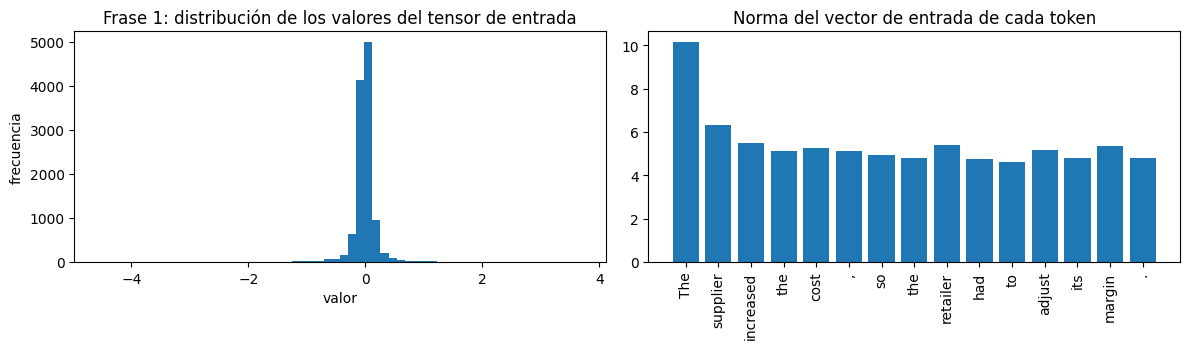

Frase 2: The store applied a promotion to the product because it was selling slowly.
Tokens: ['The', 'store', 'applied', 'a', 'promotion', 'to', 'the', 'product', 'because', 'it', 'was', 'selling', 'slowly', '.']
input_ids: [[464, 3650, 5625, 257, 12148, 284, 262, 1720, 780, 340, 373, 6301, 6364, 13]]
Tensor de entrada (ids): forma (1, 14) | dtype int64 | id mín/máx: 13 / 12148
Entrada al primer bloque (embeddings): {'forma': (1, 14, 768), 'dtype': 'float32', 'min': -4.5624, 'max': 3.7031, 'media': -0.0026, 'desv': 0.2033}
Logits de toda la frase (un vector por posición): (1, 14, 50257)


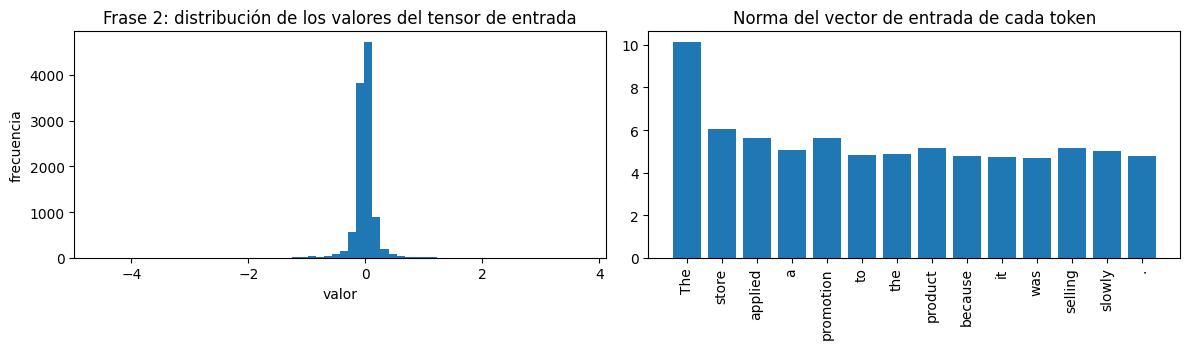

In [22]:
def limpiar(t):
    return t.replace("Ġ", "").replace("▁", "").replace("Ċ", "\\n")

def tokenizar(texto):
    enc = tokenizer(texto, return_tensors="pt")
    ids = enc["input_ids"].to(model.device)
    toks = [limpiar(t) for t in tokenizer.convert_ids_to_tokens(ids[0])]
    return ids, toks

def estadisticas(x):
    dt = x.dtype
    x = x.detach().float().cpu()
    return {"forma": tuple(x.shape), "dtype": str(dt).replace("torch.", ""),
            "min": round(x.min().item(), 4), "max": round(x.max().item(), 4),
            "media": round(x.mean().item(), 4), "desv": round(x.std().item(), 4)}

for i, s in enumerate(SENTENCES, 1):
    ids, toks = tokenizar(s["text"])
    print("=" * 78)
    print(f"Frase {i}: {s['text']}")
    print("Tokens:", toks)
    print("input_ids:", ids.tolist())
    print("Tensor de entrada (ids): forma", tuple(ids.shape), "| dtype", str(ids.dtype).replace("torch.", ""),
          "| id mín/máx:", ids.min().item(), "/", ids.max().item())
    with torch.no_grad():
        out = model(ids, output_hidden_states=True)
    h0 = out.hidden_states[0]          # lo que recibe el primer bloque (embeddings)
    print("Entrada al primer bloque (embeddings):", estadisticas(h0))
    print("Logits de toda la frase (un vector por posición):", tuple(out.logits.shape))

    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    ax[0].hist(h0.float().cpu().flatten().numpy(), bins=60)
    ax[0].set_title(f"Frase {i}: distribución de los valores del tensor de entrada")
    ax[0].set_xlabel("valor"); ax[0].set_ylabel("frecuencia")
    norms = h0[0].float().cpu().norm(dim=-1).numpy()
    ax[1].bar(range(len(toks)), norms)
    ax[1].set_xticks(range(len(toks))); ax[1].set_xticklabels(toks, rotation=90)
    ax[1].set_title("Norma del vector de entrada de cada token")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/frase{i}_entrada.png", dpi=150, bbox_inches="tight")
    plt.show()

Frase 1. Texto generado: The supplier increased the cost, so the retailer had to adjust its margin.

The company said it would not be able
Forma del vector de logits por paso: (50257,) (un valor por token del vocabulario)


,paso,token elegido,logit min,logit max,logit media,logit desv,prob. top-1,entropía
0,0,\n,-174.33,-126.73,-146.54,5.80,0.387,3.64
1,1,\n,-333.64,-252.92,-281.80,5.80,0.999,0.01
2,2,The,-153.50,-99.44,-121.40,5.97,0.156,5.25
3,3,company,-127.51,-102.44,-115.37,3.38,0.097,6.94
4,4,said,-154.66,-120.92,-137.07,3.62,0.135,4.79
5,5,it,-103.39,-72.13,-88.33,3.41,0.435,2.97
6,6,would,-175.10,-133.50,-151.66,4.36,0.115,4.57
7,7,not,-189.70,-145.69,-164.14,4.62,0.060,5.33
8,8,be,-186.35,-139.81,-159.41,4.71,0.142,5.05
9,9,able,-155.97,-123.08,-140.67,4.22,0.190,5.05


  paso 0: top-5 = [('\\n', 0.387), ('The', 0.132), ('But', 0.032), ('That', 0.028), ('In', 0.022)]
  paso 1: top-5 = [('\\n', 0.999), ('.', 0.0), ('"', 0.0), (',', 0.0), ('-', 0.0)]
  paso 2: top-5 = [('The', 0.156), ('"', 0.142), ('In', 0.036), ('But', 0.027), ('A', 0.015)]
  paso 3: top-5 = [('company', 0.097), ('retailer', 0.058), ('cost', 0.017), ('new', 0.016), ('price', 0.015)]
  paso 4: top-5 = [('said', 0.135), ('also', 0.093), ("'s", 0.083), ('has', 0.042), ('is', 0.034)]
  paso 5: top-5 = [('it', 0.435), ('the', 0.168), ('that', 0.072), ('its', 0.047), ('in', 0.038)]
  paso 6: top-5 = [('would', 0.115), ('was', 0.115), ('had', 0.091), ('will', 0.049), ('is', 0.035)]
  paso 7: top-5 = [('not', 0.06), ('be', 0.046), ('pay', 0.044), ('continue', 0.044), ('also', 0.028)]
  paso 8: top-5 = [('be', 0.142), ('comment', 0.047), ('disclose', 0.044), ('change', 0.034), ('sell', 0.031)]
  paso 9: top-5 = [('able', 0.19), ('making', 0.04), ('taking', 0.033), ('liable', 0.031), ('responsi

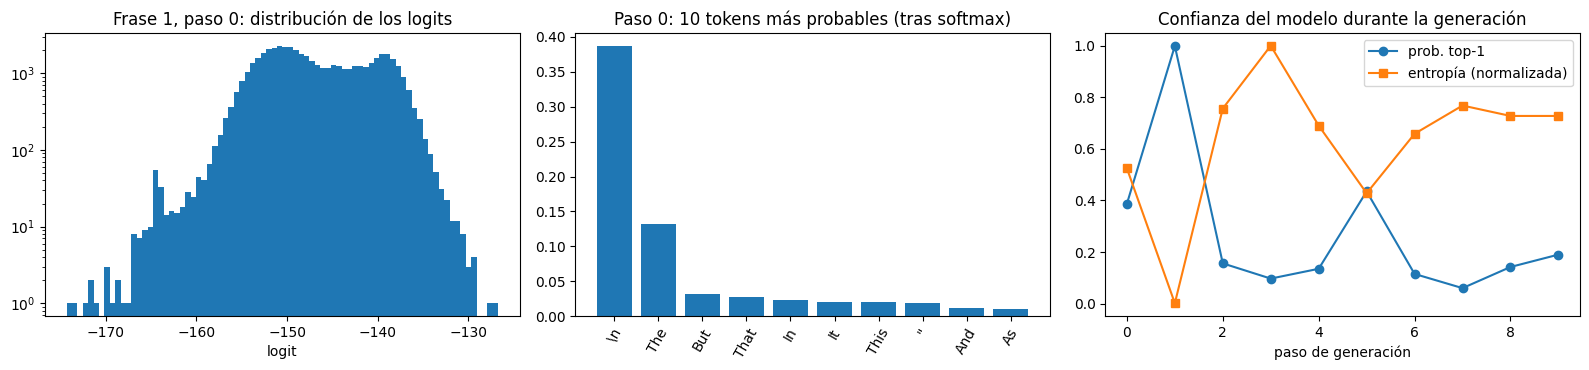

Frase 2. Texto generado: The store applied a promotion to the product because it was selling slowly.

"We were told that the promotion was
Forma del vector de logits por paso: (50257,) (un valor por token del vocabulario)


,paso,token elegido,logit min,logit max,logit media,logit desv,prob. top-1,entropía
0,0,\n,-177.00,-130.71,-149.57,5.41,0.275,4.11
1,1,\n,-321.58,-247.78,-275.14,5.95,0.999,0.02
2,2,"""",-145.32,-94.97,-115.94,5.46,0.202,5.07
3,3,We,-176.82,-128.91,-149.72,4.87,0.208,3.87
4,4,were,-197.11,-156.27,-173.63,3.88,0.091,4.70
5,5,told,-180.56,-146.91,-162.93,4.24,0.054,5.48
6,6,that,-137.86,-104.95,-121.52,3.40,0.235,3.20
7,7,the,-160.36,-124.46,-139.52,3.87,0.151,4.27
8,8,promotion,-137.30,-106.63,-120.96,3.86,0.142,5.62
9,9,was,-167.80,-127.14,-145.60,4.19,0.397,3.21


  paso 0: top-5 = [('\\n', 0.275), ('The', 0.121), ('It', 0.051), ('But', 0.037), ('"', 0.027)]
  paso 1: top-5 = [('\\n', 0.999), ('"', 0.0), ('The', 0.0), ('.', 0.0), ('A', 0.0)]
  paso 2: top-5 = [('"', 0.202), ('The', 0.131), ('A', 0.023), ('But', 0.023), ('In', 0.022)]
  paso 3: top-5 = [('We', 0.208), ('I', 0.132), ('It', 0.099), ('The', 0.066), ('They', 0.038)]
  paso 4: top-5 = [('were', 0.091), ("'re", 0.087), ('are', 0.051), ("'ve", 0.048), ('have', 0.045)]
  paso 5: top-5 = [('told', 0.054), ('trying', 0.033), ('just', 0.032), ('very', 0.029), ('looking', 0.025)]
  paso 6: top-5 = [('that', 0.235), ('by', 0.109), ('it', 0.108), ('to', 0.083), ('we', 0.081)]
  paso 7: top-5 = [('the', 0.151), ('we', 0.097), ('it', 0.095), ('if', 0.076), ('they', 0.071)]
  paso 8: top-5 = [('promotion', 0.142), ('store', 0.117), ('product', 0.062), ('price', 0.025), ('company', 0.023)]
  paso 9: top-5 = [('was', 0.397), ('would', 0.16), ('had', 0.065), ('is', 0.027), ('will', 0.017)]


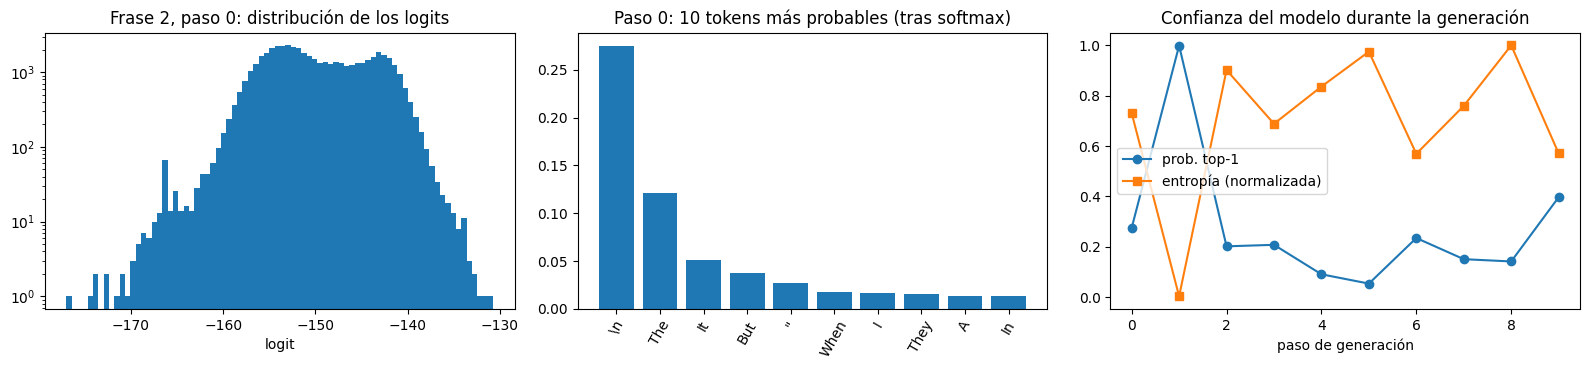

In [23]:
@torch.no_grad()
def generar_con_logits(texto, n_nuevos):
    ids, _ = tokenizar(texto)
    filas, logits_pasos = [], []
    for paso in range(n_nuevos):
        lg = model(ids).logits[0, -1].float().cpu()          # logits del siguiente token
        pr = torch.softmax(lg, dim=-1)
        top5 = torch.topk(pr, 5)
        sig = int(lg.argmax())                               # generación "greedy"
        ent = float(-(pr * torch.log(pr + 1e-12)).sum())
        filas.append({
            "paso": paso,
            "token elegido": limpiar(tokenizer.convert_ids_to_tokens(sig)),
            "logit min": round(lg.min().item(), 2), "logit max": round(lg.max().item(), 2),
            "logit media": round(lg.mean().item(), 2), "logit desv": round(lg.std().item(), 2),
            "prob. top-1": round(pr.max().item(), 3), "entropía": round(ent, 2),
            "top-5": [(limpiar(tokenizer.convert_ids_to_tokens(int(j))), round(float(p), 3))
                      for p, j in zip(top5.values, top5.indices)],
        })
        logits_pasos.append(lg)
        ids = torch.cat([ids, torch.tensor([[sig]], device=ids.device)], dim=1)
    return ids, pd.DataFrame(filas), logits_pasos

pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
for i, s in enumerate(SENTENCES, 1):
    ids, df, lps = generar_con_logits(s["text"], N_NEW_TOKENS)
    print("=" * 78)
    print(f"Frase {i}. Texto generado:", tokenizer.decode(ids[0], skip_special_tokens=True))
    print("Forma del vector de logits por paso:", tuple(lps[0].shape), "(un valor por token del vocabulario)")
    display(df.drop(columns="top-5"))
    for _, r in df.iterrows():
        print(f"  paso {r['paso']}: top-5 = {r['top-5']}")
    df.drop(columns="top-5").to_csv(f"{OUT_DIR}/frase{i}_logits_pasos.csv", index=False)

    lg0 = lps[0]; pr0 = torch.softmax(lg0, -1)
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    ax[0].hist(lg0.numpy(), bins=80); ax[0].set_yscale("log")
    ax[0].set_title(f"Frase {i}, paso 0: distribución de los logits"); ax[0].set_xlabel("logit")
    t10 = torch.topk(pr0, 10)
    ax[1].bar(range(10), t10.values.numpy())
    ax[1].set_xticks(range(10)); ax[1].set_xticklabels([limpiar(tokenizer.convert_ids_to_tokens(int(j))) for j in t10.indices], rotation=60)
    ax[1].set_title("Paso 0: 10 tokens más probables (tras softmax)")
    ax[2].plot(df["paso"], df["prob. top-1"], marker="o", label="prob. top-1")
    ax[2].plot(df["paso"], df["entropía"] / df["entropía"].max(), marker="s", label="entropía (normalizada)")
    ax[2].set_xlabel("paso de generación"); ax[2].legend(); ax[2].set_title("Confianza del modelo durante la generación")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/frase{i}_logits.png", dpi=150, bbox_inches="tight")
    plt.show()

### Análisis de la entrada y de los logits

**Logits.** En cada paso de la generación el modelo devuelve un vector de 50,257 logits (forma `(50257,)`), uno por token del vocabulario. En las dos frases todos los valores son negativos (por ejemplo, entre −333.6 y −72.1 en la frase 1) y su desviación estándar es de 3.4 a 6.0. Esto confirma que los logits no son probabilidades: no están acotados, pueden ser muy negativos y no suman 1. Como el softmax solo depende de las **diferencias** entre logits (P_i / P_j = e^(z_i − z_j)), el nivel absoluto no importa. Por ejemplo, en la frase 1, paso 5, "it" (0.435) y "the" (0.168) difieren en ln(0.435/0.168) ≈ 0.95 unidades de logit. Lo que sí influye es cuánto se separa el máximo del resto: la diferencia entre el logit máximo y la media va de 12.9 a 28.9, y es mayor justo en los pasos en que el modelo está más seguro.

**Probabilidad y entropía.** Tras el softmax, la probabilidad del token elegido (top-1) varía mucho: de 0.060 a 0.435 en la frase 1 y de 0.054 a 0.397 en la frase 2 (sin contar el paso 1). La entropía (en nats; el máximo posible sería ln 50,257 ≈ 10.8) va de 2.97 a 6.94 y de 3.20 a 5.62, es decir, el modelo nunca reparte la probabilidad de forma uniforme, pero en muchos pasos duda entre varias palabras. Se ve un patrón: la entropía es más alta en palabras de contenido ("company" 6.94, "promotion" 5.62, "told" 5.48) y más baja en palabras funcionales ("it" 2.97, "that" 3.20, "was" 3.21), cuya gramática restringe más las opciones.

**Saltos de línea.** En ambas frases los pasos 0 y 1 eligen `\n`: primero con probabilidad 0.387 y 0.275, y luego con 0.999 (entropía 0.01-0.02). Tras un punto final, el modelo espera un salto de línea y, una vez generado el primero, casi seguro genera un segundo. Es probable que se deba a que, en los textos de entrenamiento, una frase terminada en punto suele ir seguida de un nuevo párrafo.

**Texto generado y uso del contexto.** En la frase 1 el modelo continúa con "The company said it would not be able" y en la frase 2 con «"We were told that the promotion was». Son textos gramaticales pero no continúan la idea de la frase de entrada, sino que abren un párrafo nuevo. Sin embargo, el modelo sí usa el contexto: en la frase 1, paso 3, el segundo candidato es "retailer" (0.058) y entre los cinco primeros están "cost" y "price", palabras de la entrada; y en la frase 2, paso 8, elige "promotion", que aparece en la frase original. Por último, la generación *greedy* siempre elige el token más probable aunque sea muy poco probable en términos absolutos (por ejemplo "told", con 0.054), lo que explica que el texto sea correcto pero poco coherente con el tema.

## 4. Mapas de calor de la self-attention

Cada mapa es la matriz `softmax(QKᵀ/√dk)` de una capa y una cabeza: la **fila** es el token que atiende (query), la **columna** el token atendido (key), y cada fila suma 1. La función de la self-attention es que cada token construya su representación como una **mezcla ponderada de los tokens anteriores**, decidiendo cuánto mira a cada uno. Como GPT-2 es un *decoder* con máscara causal (sección 3.2.3 del paper), los mapas son **triangulares**: un token solo mira a los anteriores y a sí mismo. Con varias cabezas por capa, cada una puede especializarse en una relación distinta.

Se muestran, para cada frase: (a) el promedio de las cabezas en una capa baja, una media y una alta; (b) cabezas individuales de una capa intermedia; (c) las cabezas con patrones típicos (atender al token anterior o al primer token); (d) la atención de la palabra de interés, capa por capa.

Frase 1: The supplier increased the cost, so the retailer had to adjust its margin.
Tensor de atención: (capas, cabezas, n, n) = (12, 12, 15, 15)


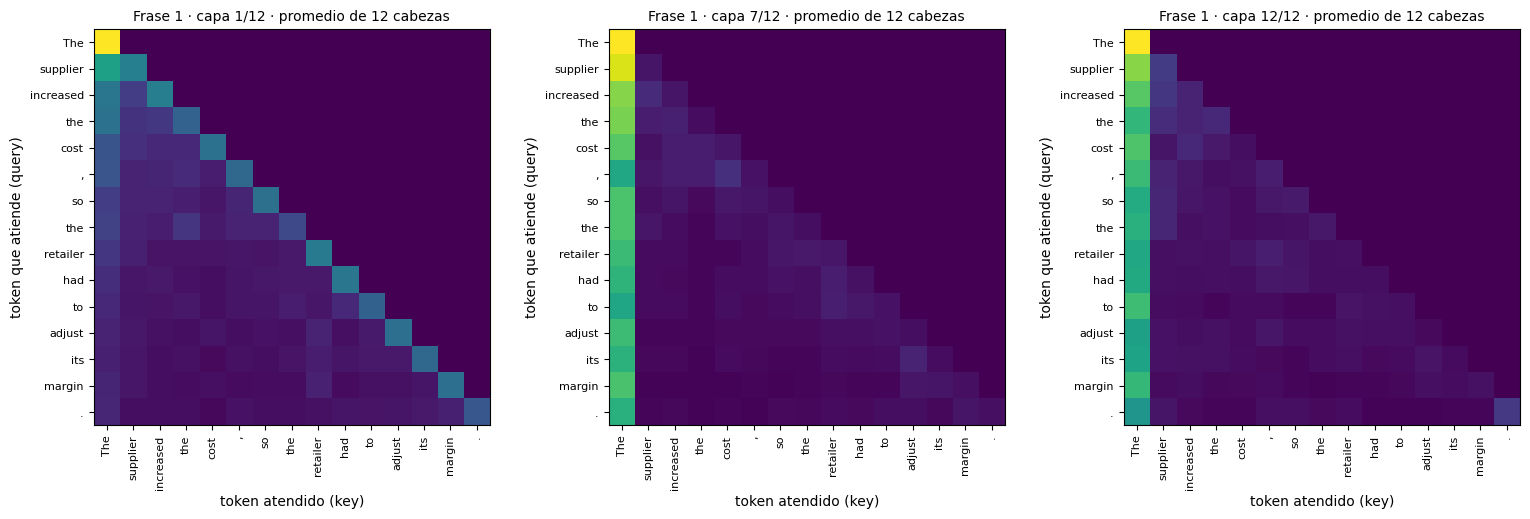

In [ ]:
@torch.no_grad()
def atenciones(texto):
    ids, toks = tokenizar(texto)
    out = model(ids, output_attentions=True)
    if out.attentions is None or out.attentions[0] is None:
        raise RuntimeError("El modelo no devolvió atenciones: cárgalo con attn_implementation='eager'.")
    att = torch.stack([a[0].float().cpu() for a in out.attentions])     # (capas, cabezas, n, n)
    return att, toks

def heat(ax, M, toks, titulo, cmap="viridis"):
    M = M.numpy() if hasattr(M, "numpy") else M
    ax.imshow(M, cmap=cmap, vmin=0, vmax=max(float(M.max()), 1e-6))
    ax.set_xticks(range(len(toks))); ax.set_xticklabels(toks, rotation=90, fontsize=8)
    ax.set_yticks(range(len(toks))); ax.set_yticklabels(toks, fontsize=8)
    ax.set_xlabel("token atendido (key)"); ax.set_ylabel("token que atiende (query)")
    ax.set_title(titulo, fontsize=10)

def perfiles(att):
    L, H, n, _ = att.shape
    idx = torch.arange(1, n)
    prev    = att[:, :, idx, idx - 1].mean(-1)                         # atiende al token anterior
    primero = att[:, :, idx, 0].mean(-1)                               # atiende al primer token
    propio  = att[:, :, torch.arange(n), torch.arange(n)].mean(-1)     # se atiende a sí mismo
    return prev, primero, propio

def top_cabezas(S, k=3):
    H = S.shape[1]
    v, ix = torch.topk(S.flatten(), k)
    return [(int(j) // H, int(j) % H, round(float(x), 3)) for x, j in zip(v, ix)]   # (capa, cabeza, puntaje)

def fila_query(att, toks, palabra):
    cand = [i for i, t in enumerate(toks) if t.lower() == palabra.lower()]
    if not cand:
        print(f"  (aviso: '{palabra}' no es un token propio; uso el último token)")
    return (cand[-1] if cand else len(toks) - 1)

for i, s in enumerate(SENTENCES, 1):
    att, toks = atenciones(s["text"])
    L, H, n, _ = att.shape
    print("=" * 78)
    print(f"Frase {i}: {s['text']}")
    print("Tensor de atención: (capas, cabezas, n, n) =", tuple(att.shape))

    # (a) Promedio de cabezas en capa baja, media y alta
    capas = sorted(set([0, L // 2, L - 1]))
    fig, axs = plt.subplots(1, len(capas), figsize=(5.2 * len(capas), 5))
    for ax, l in zip(np.atleast_1d(axs), capas):
        heat(ax, att[l].mean(0), toks, f"Frase {i} · capa {l + 1}/{L} · promedio de {H} cabezas")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/frase{i}_capas_promedio.png", dpi=150, bbox_inches="tight"); plt.show()

    # (b) Cabezas individuales de una capa intermedia
    capa_det = L // 2
    mostrar_h = list(range(min(H, 12)))
    filas = int(np.ceil(len(mostrar_h) / 4))
    fig, axs = plt.subplots(filas, 4, figsize=(18, 4.6 * filas))
    for ax in np.atleast_1d(axs).flatten()[len(mostrar_h):]:
        ax.axis("off")
    for ax, h in zip(np.atleast_1d(axs).flatten(), mostrar_h):
        heat(ax, att[capa_det, h], toks, f"capa {capa_det + 1} · cabeza {h + 1}")
    plt.suptitle(f"Frase {i}: cabezas individuales de la capa {capa_det + 1}", y=1.0)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/frase{i}_cabezas_capa{capa_det + 1}.png", dpi=130, bbox_inches="tight"); plt.show()

    # (c) ¿Qué función cumplen las cabezas? Buscamos patrones típicos.
    prev, primero, propio = perfiles(att)
    print("Cabezas que más atienden al TOKEN ANTERIOR (capa, cabeza, puntaje):", top_cabezas(prev))
    print("Cabezas que más atienden al PRIMER token   (capa, cabeza, puntaje):", top_cabezas(primero))
    print("Cabezas que más se atienden a SÍ MISMAS    (capa, cabeza, puntaje):", top_cabezas(propio))
    lp, hp, _ = top_cabezas(prev, 1)[0]
    lf, hf, _ = top_cabezas(primero, 1)[0]
    fig, axs = plt.subplots(1, 2, figsize=(11, 5))
    heat(axs[0], att[lp, hp], toks, f"'token anterior' · capa {lp + 1}, cabeza {hp + 1}")
    heat(axs[1], att[lf, hf], toks, f"'primer token' · capa {lf + 1}, cabeza {hf + 1}")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/frase{i}_patrones.png", dpi=150, bbox_inches="tight"); plt.show()

    # (d) A quién atiende la palabra de interés, capa por capa
    q = fila_query(att, toks, s["query"])
    M = att[:, :, q, :].mean(1)                       # (capas, n): promedio de cabezas
    M2 = M.clone(); M2[:, 0] = 0
    M2 = M2 / M2.sum(-1, keepdim=True).clamp_min(1e-9)   # sin el primer token, renormalizado
    fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))
    for ax, MM, t in zip(axs, [M, M2], ["promedio de cabezas", "sin el primer token (renormalizado)"]):
        ax.imshow(MM.numpy(), aspect="auto", cmap="viridis", vmin=0, vmax=max(float(MM.max()), 1e-6))
        ax.set_xticks(range(n)); ax.set_xticklabels(toks, rotation=90, fontsize=8)
        paso_y = max(1, L // 12)
        ax.set_yticks(range(0, L, paso_y)); ax.set_yticklabels([str(k + 1) for k in range(0, L, paso_y)])
        ax.set_ylabel("capa"); ax.set_xlabel("token atendido")
        ax.set_title(f"Frase {i}: atención de '{toks[q]}' · {t}", fontsize=10)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/frase{i}_query_{s['query']}.png", dpi=150, bbox_inches="tight"); plt.show()
    for l in sorted(set([L // 2, L - 1])):
        k = min(3, q + 1)
        v, ix = torch.topk(M2[l, :q + 1], k)
        print(f"  capa {l + 1}: '{toks[q]}' atiende (sin 1er token) a:",
              [(toks[int(j)], round(float(x), 3)) for x, j in zip(v, ix)])

### Análisis de los mapas de atención

**Capas bajas vs. altas.** En la capa 1 el promedio de las cabezas muestra una diagonal marcada: cada token atiende sobre todo a sí mismo, además de al primer token. A partir de la capa 7, y todavía más en la 12, casi toda la atención se concentra en la primera columna, es decir, en el primer token ("The"). En todos los mapas la matriz es triangular: por la máscara causal, ningún token atiende a los posteriores.

**Cabezas con funciones distintas.** El código mide qué cabezas dedican más atención a un patrón concreto (capa, cabeza; puntaje de 0 a 1):

| Patrón | Capa, cabeza | Frase 1 | Frase 2 |
| --- | --- | --- | --- |
| Token anterior | 5, 12 | 1.000 | 0.999 |
| Primer token | 6, 2 | 0.995 | 0.994 |
| Primer token | 8, 3 | 0.987 | 0.993 |
| Primer token | 7, 10 | 0.985 | 0.991 |
| Sí mismo | 1, 2 | 0.947 | 0.972 |
| Sí mismo | 1, 4 | 0.848 | 0.825 |

- La cabeza **5-12** atiende prácticamente solo al token inmediatamente anterior (diagonal desplazada en su mapa): permite que cada palabra "sepa" cuál la precede.
- Las cabezas **6-2, 8-3 y 7-10** dejan casi toda su atención en el primer token. Como el softmax obliga a que cada fila sume 1, una cabeza que no tiene nada útil que mirar puede "descansar" en un token fijo (en la literatura, un *attention sink*).
- Las cabezas **1-2 y 1-4** se atienden a sí mismas: en la primera capa conservan la identidad del propio token.
- Las mismas cabezas aparecen con la misma función en las dos frases, así que ese comportamiento es propio de la cabeza y no de la frase. En la capa 7, las cabezas 10 y 11 miran casi solo al primer token, mientras que otras (por ejemplo 9 y 12) muestran además relaciones puntuales entre pares de palabras y bandas cercanas a la diagonal.

**Palabra de interés.** Al quitar el primer token y renormalizar, se ve a qué otras palabras atiende:
- *Frase 1, `its` (debería apuntar a `retailer`).* En la capa 7 atiende sobre todo a `adjust` (0.271), que es el token anterior; `retailer` es segundo (0.092), casi empatado con el propio `its` (0.091). En la capa 12 los primeros son `adjust` (0.121), `supplier` (0.116) y `the` (0.108), y `retailer` no aparece. Por tanto, GPT-2 no resuelve claramente la referencia, y la señal dominante es local. En el mapa se ve una activación moderada en `retailer` en las capas 5 y 10.
- *Frase 2, `it` (debería apuntar a `product` o `store`).* En la capa 7 domina `because` (0.285), el token anterior, seguido de `store` (0.128) y `promotion` (0.122). En la capa 12 los dos primeros son `store` (0.164) y `product` (0.151), por delante de `because` (0.144). En las capas finales, `it` reparte atención entre los dos sustantivos candidatos, lo que refleja la ambigüedad de la frase, sin preferir claramente a ninguno.
- En ambas frases, el pico de atención al token anterior (`adjust`, `because`) ocurre en las capas 3 a 5, donde están las cabezas de "token anterior" (5-12, 3-3 y 4-3).

**¿Lo esperaba?** En parte. Esperaba mapas triangulares (sección 3.2.3 del paper), cabezas con funciones distintas (el paper afirma que cabezas distintas aprenden tareas distintas) y patrones más locales en las capas bajas. No esperaba que casi toda la atención de las capas medias y altas acabara en el primer token, ni que un modelo entrenado resolviera tan poco la referencia de `its` / `it`. Esto es razonable por dos motivos: GPT-2 pequeño es un modelo modesto, y la atención no explica por sí sola lo que calcula el modelo, ya que la información también pasa por los valores V, las conexiones residuales y las redes feed-forward. Además, son solo dos frases, así que las conclusiones son ilustrativas.

## 5. Conclusiones


**Conclusiones**

1. **Arquitectura y tamaño.** GPT-2 pequeño usa solo la parte decodificadora del Transformer de Vaswani et al. (2017): 12 bloques, 12 cabezas de atención y d_model = 768. Suma 124,439,808 parámetros. La suma por capas coincide con la que calculé a mano. Los bloques concentran 85 M (unos 7.09 M cada uno), y el embedding de tokens aporta 38.6 M. Como la capa de salida comparte pesos con ese embedding, no añade parámetros nuevos.

2. **Entrada y logits.** El texto se convierte en identificadores de tokens y luego en vectores de 768 dimensiones. A partir de ahí, cada token queda representado por un vector que las capas van refinando. Al final, el modelo produce un logit por cada palabra del vocabulario (50,257). Los logits no son probabilidades: el softmax los convierte en una distribución. En la generación greedy se elige siempre el token de mayor logit. [Añade aquí 1 o 2 datos de tus tablas, por ejemplo el rango de los logits y la probabilidad del token elegido.]

3. **Atención.** Los mapas son triangulares por la máscara causal, como se esperaba. Las cabezas están especializadas: una atiende al token anterior (capa 5, cabeza 12, ≈ 1.0), otras se anclan al primer token (capa 6, cabeza 2, ≈ 0.99) y otras a sí mismas en la primera capa (capa 1, cabeza 2, ≈ 0.95 a 0.97). Esas funciones se repiten en las dos frases, lo que indica que son propias de cada cabeza y no de la frase.

4. **Resolución de referencias.** En mis dos frases, `its` y `it` prestan atención sobre todo al token inmediatamente anterior y reparten el resto entre varios sustantivos (`store` y `product` en la frase 2). La atención por sí sola no basta para afirmar que el modelo "resuelve" la referencia. En este modelo pequeño la señal es débil.

5. **Limitaciones.** El análisis usa solo dos frases y un modelo pequeño, así que los resultados son ilustrativos y no generalizables. Además, la atención solo muestra una parte de lo que calcula el modelo, ya que también influyen los valores V, las conexiones residuales y las capas feed-forward.

6. **Aprendizaje.** El ejercicio me permitió ver de forma concreta lo que dice el paper: la atención como matriz de pesos entre tokens, la importancia de las cabezas múltiples y cómo se reparten los parámetros entre atención, feed-forward y embeddings.

## Referencias

- Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). *Attention Is All You Need*. Advances in Neural Information Processing Systems 30. arXiv:1706.03762.
- Radford, A., Wu, J., Child, R., Luan, D., Amodei, D., & Sutskever, I. (2019). *Language Models are Unsupervised Multitask Learners*. OpenAI.
- Wolf, T., et al. (2020). *Transformers: State-of-the-Art Natural Language Processing*. Proceedings of EMNLP 2020: System Demonstrations, 38–45.
- Hugging Face. *openai-community/gpt2* (modelo y pesos). https://huggingface.co/openai-community/gpt2